## 1. Import thư viện và nạp dữ liệu vào notebook

In [60]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
wine_data = pd.read_csv("data/winequality-red.csv")
wine_data = wine_data[[
    'fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
    'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
    'pH', 'sulphates', 'alcohol', 'quality'
]]

## 2. Kiểm tra nhanh dữ liệu
+ Xem 5 dòng đầu tiên của dữ liệu.
+ Kiểm tra kiểu dữ liệu các cột.
+ Kiểm tra kích thước (số dòng, số cột) của tập dữ liệu.

In [61]:
wine_data.head(5)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [62]:
print(wine_data.info())

<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB
None


In [63]:
wine_data.dtypes


fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object

In [64]:
wine_data.shape

(1599, 12)

## 3. Làm sạch dữ liệu (Data Cleaning)
+ Tiến hành xử lý dữ liệu trùng lặp và dữ liệu thiếu.
+ các cột trong bài đều quan trọng, không cần xóa

### 3.1. Loại bỏ các dòng bị trùng lặp hoàn toàn trên tất cả các cột

In [65]:
# Lọc bỏ trùng lặp và gán trực tiếp vào tập dữ liệu sạch
wine_data = wine_data.drop_duplicates()
wine_data.shape

(1359, 12)

### 3.2. Kiểm tra và xử lý dữ liệu thiếu (Missing values)


In [66]:
# Kiểm tra số lượng ô trống (NaN) trên từng cột
wine_data.isnull().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

## 4. Thay thế dữ liệu và chuẩn hóa định dạng (Data Transformation)
+ Phân nhóm điểm chất lượng (quality) từ thang số 3-8 sang dạng chữ ('Low', 'Medium', 'High') để dễ phân tích.
+ bài này có quality int sẵn rồi ko cần đổi
+ bài này không có dữ liệu khuyết nên không cần điền khuyết bằng số 0

### 4.1. Thay thế giá trị cột quality thành nhãn chữ ('Low', 'Medium', 'High')

In [67]:
wine_data['quality_replaced'] = wine_data['quality'].replace(
    [3, 4, 5, 6, 7, 8], 
    ['Low', 'Low', 'Medium', 'Medium', 'High', 'High']
)

## 5. Tính toán các chỉ số thống kê mô tả (Descriptive Statistics)
+ Chọn cột alcohol (nồng độ cồn) làm biến định lượng đại diện.

### 5.1. Tính giá trị trung bình (Mean)

In [68]:
data_mean = np.mean(wine_data["alcohol"])

### 5.2. Tính giá trị trung vị (Median)

In [69]:
data_median = np.median(wine_data["alcohol"])

### 5.3. Tìm yếu vị / giá trị xuất hiện nhiều nhất (Mode)

In [70]:
data_mode = stats.mode(wine_data["alcohol"])

### 5.4. Tính phương sai (Variance)

In [71]:
data_variance = np.var(wine_data["alcohol"])

### 5.5. Tính độ lệch chuẩn (Standard Deviation)

In [72]:
data_sd = np.std(wine_data["alcohol"])

### 5.6. Tìm giá trị lớn nhất (Max) và nhỏ nhất (Min)

In [73]:
data_max = np.max(wine_data["alcohol"])
data_min = np.min(wine_data["alcohol"])

### 5.7. Tính bách phân vị thứ 60 (60th Percentile)

In [74]:
data_percentile = np.percentile(wine_data["alcohol"], 60)

### 5.8. Tính tứ phân vị Q3 (75th Percentile)

In [75]:
data_quartile = np.quantile(wine_data["alcohol"], 0.75)

### 5.9. Tính khoảng tứ phân vị (IQR)

In [76]:
data_IQR = stats.iqr(wine_data["alcohol"])

In [77]:
print(f"Mean: {data_mean}")
print(f"Median: {data_median}")
print(f"Mode: {np.ravel(data_mode.mode)[0]}")
print(f"Variance: {data_variance}")
print(f"Standard Deviation: {data_sd}")
print(f"Min: {data_min} | Max: {data_max}")
print(f"Range: {data_max - data_min}")
print(f"60th Percentile: {data_percentile}")
print(f"Q3 (75th Percentile): {data_quartile}")
print(f"IQR: {data_IQR}")

Mean: 10.432315428010792
Median: 10.2
Mode: 9.5
Variance: 1.170004073835233
Standard Deviation: 1.0816672657685602
Min: 8.4 | Max: 14.9
Range: 6.5
60th Percentile: 10.5
Q3 (75th Percentile): 11.1
IQR: 1.5999999999999996


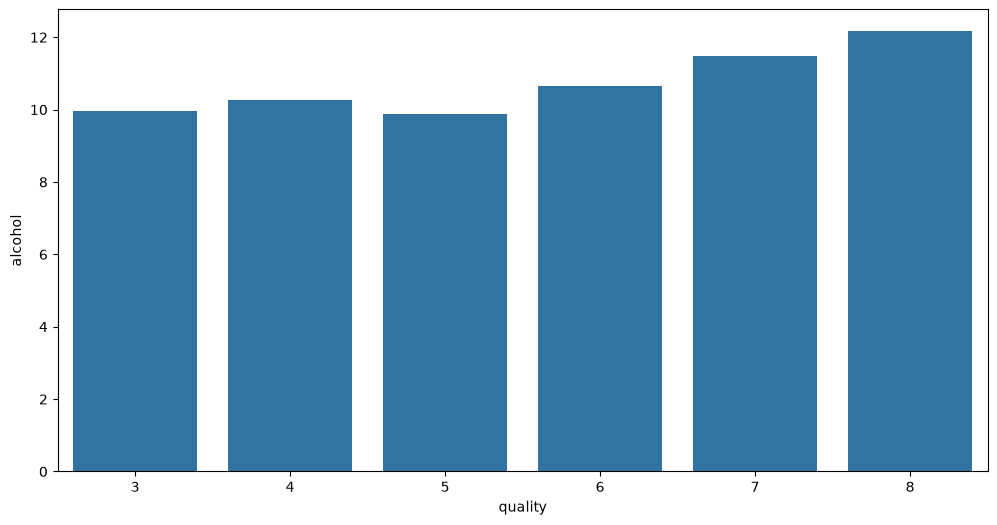

C:\Users\BAO\AppData\Local\Temp\ipykernel_29708\4018195914.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


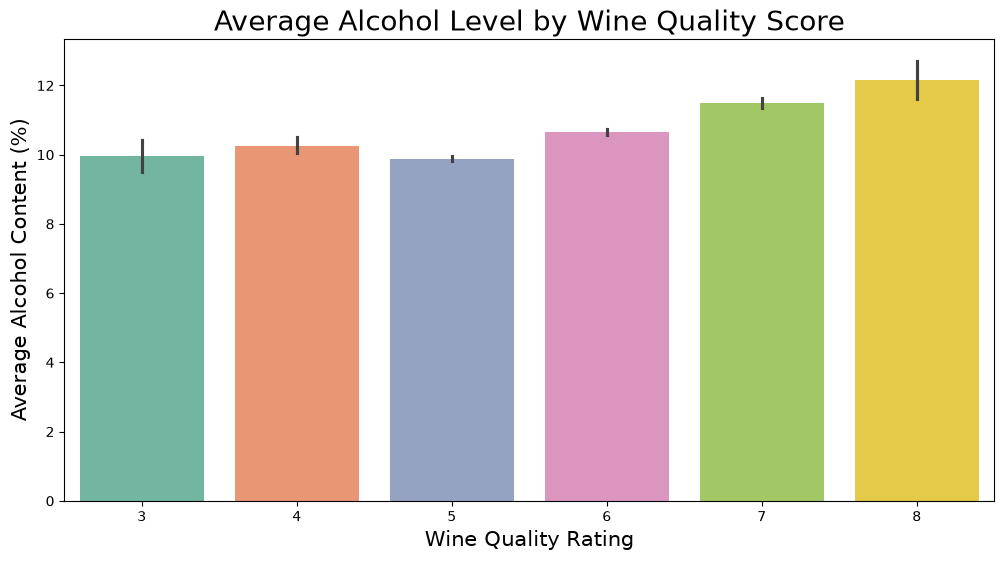

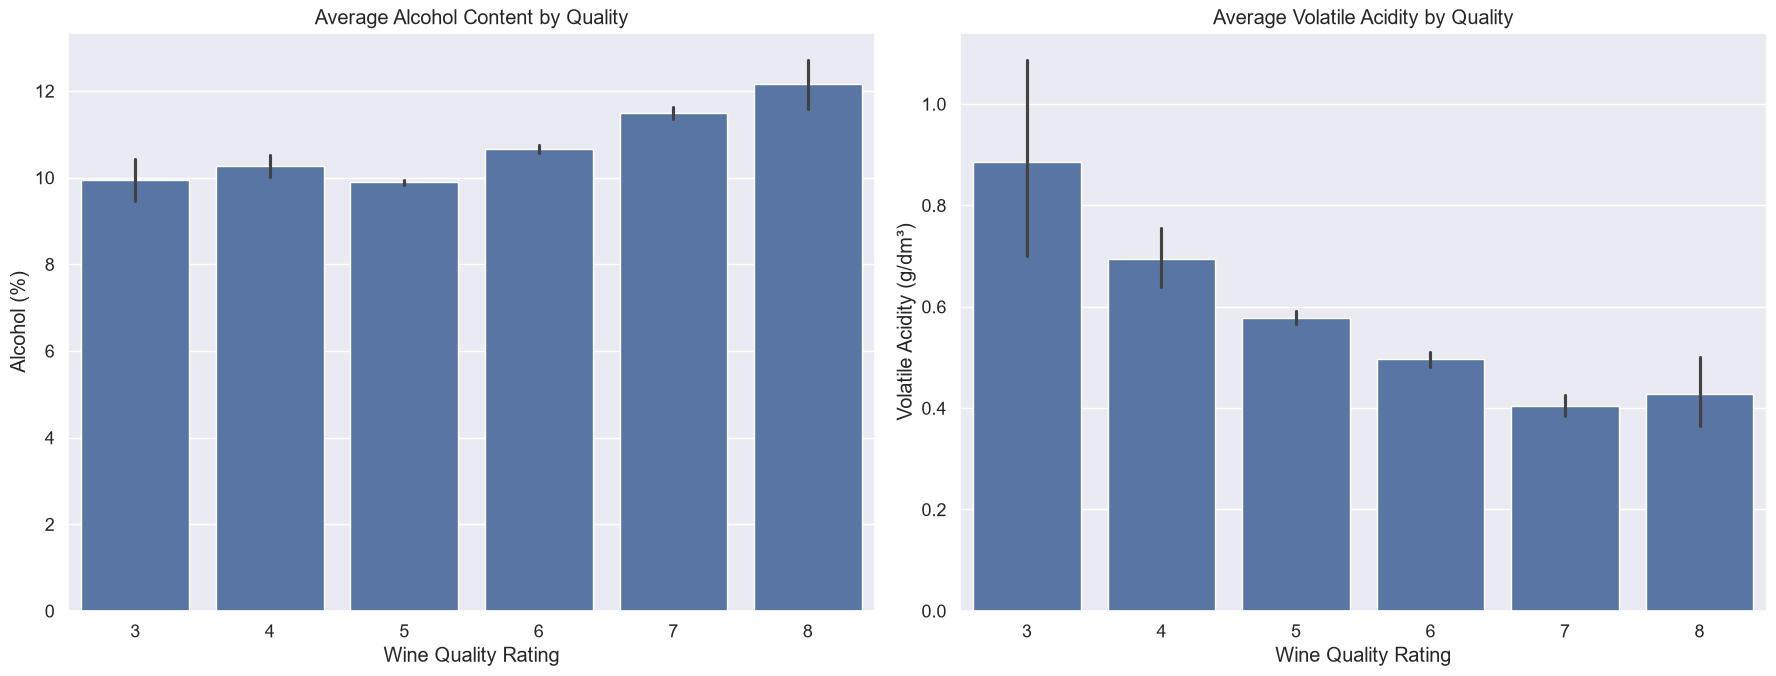

In [78]:
data = wine_data

# --- Case 1: Basic ---
plt.figure(figsize=(12, 6))
sns.barplot(data=data, x="quality", y="alcohol", errorbar=None)
plt.show()

# --- Case 2: Advanced 1 ---
plt.figure(figsize=(12, 6))
ax = sns.barplot(
    data=data, x="quality", y="alcohol", palette="Set2"
)  # <--- Bỏ hue="type" ở đây nè
ax.set_xlabel("Wine Quality Rating", fontsize=15)
ax.set_ylabel("Average Alcohol Content (%)", fontsize=15)
ax.set_title("Average Alcohol Level by Wine Quality Score", fontsize=20)
plt.show()

# --- Case 3: View multiple perspectives at once ---
sns.set_theme(font_scale=1.2)

fig, ax = plt.subplots(1, 2, figsize=(18, 7))

# Biểu đồ 1: Alcohol
ax1 = sns.barplot(
    data=data, x="quality", y="alcohol", ax=ax[0]
)  # <--- Bỏ hue="type"
ax1.set_xlabel("Wine Quality Rating")
ax1.set_ylabel("Alcohol (%)")
ax1.set_title("Average Alcohol Content by Quality")

# Biểu đồ 2: Volatile Acidity
ax2 = sns.barplot(
    data=data, x="quality", y="volatile acidity", ax=ax[1]
)  # <--- Bỏ hue="type"
ax2.set_xlabel("Wine Quality Rating")
ax2.set_ylabel("Volatile Acidity (g/dm³)")
ax2.set_title("Average Volatile Acidity by Quality")

plt.tight_layout()
plt.show()

# Reset lại theme
sns.reset_orig()